In [63]:

import numpy as np
import matplotlib.pyplot as plt

In [64]:

%%writefile my_utils.py
import numpy as np
import matplotlib.pyplot as plt

# 1. 이동
def move(tx, ty):
    return np.array([
        [1, 0, tx],
        [0, 1, ty],
        [0, 0, 1]
    ])

# 2. 회전
def rotate(degree):
    t = np.radians(degree)
    return np.array([
        [np.cos(t), -np.sin(t), 0],
        [np.sin(t), np.cos(t), 0],
        [0, 0, 1]
    ])

# 3. 크기 변환
def scale(sx, sy):
    return np.array([
        [sx, 0, 0],
        [0, sy, 0],
        [0, 0, 1]
    ])

# 4. x축 기울이기
def shear_x(k):
    return np.array([
        [1, k, 0],
        [0, 1, 0],
        [0, 0, 1]
    ])

# 5. y축 기울이기
def shear_y(k):
    return np.array([
        [1, 0, 0],
        [k, 1, 0],
        [0, 0, 1]
    ])

# 6. x축 반전
def reflect_x():
    return scale(1, -1)

# 7. y축 반전
def reflect_y():
    return scale(-1, 1)

# 8. 원점 반전
def reflect_origin():
    return scale(-1, -1)

# 9. y=x 반전
def reflect_yx():
    return np.array([
        [0, 1, 0],
        [1, 0, 0],
        [0, 0, 1]
    ])

# 네모 꼭짓점 좌표
def rectangle(x, y, w, h):
    return np.array([
        [x, x+w, x+w, x, x],
        [y, y, y+h, y+h, y],
        [1, 1, 1, 1, 1]
    ])

# 행렬 곱셈을 이용해 네모 그리기
def draw_rect(ax, x, y, w, h, color, M):
    points = rectangle(x, y, w, h)
    result = np.dot(M, points)

    ax.fill(
        result[0],
        result[1],
        color=color,
        edgecolor="black",
        linewidth=1
    )

# 네모 로봇 그리기
def draw_object(ax, M=None):

    if M is None:
        M = np.eye(3)

    # 안테나
    draw_rect(ax, -0.1, 2.3, 0.2, 0.5, "gray", M)
    draw_rect(ax, -0.2, 2.8, 0.4, 0.2, "orange", M)

    # 머리
    draw_rect(ax, -1.2, 0.9, 2.4, 1.4, "skyblue", M)

    # 눈
    draw_rect(ax, -0.8, 1.6, 0.5, 0.4, "black", M)
    draw_rect(ax, 0.3, 1.6, 0.5, 0.4, "black", M)

    # 입
    draw_rect(ax, -0.4, 1.1, 0.8, 0.15, "pink", M)

    # 몸통
    draw_rect(ax, -1, -1, 2, 1.8, "deepskyblue", M)

    # 왼팔, 오른팔
    draw_rect(ax, -1.8, -0.8, 0.6, 1.5, "skyblue", M)
    draw_rect(ax, 1.2, -0.8, 0.6, 1.5, "skyblue", M)

    # 손
    draw_rect(ax, -1.7, -1.1, 0.4, 0.3, "pink", M)
    draw_rect(ax, 1.3, -1.1, 0.4, 0.3, "pink", M)

    # 다리
    draw_rect(ax, -0.8, -2.1, 0.6, 1, "gray", M)
    draw_rect(ax, 0.2, -2.1, 0.6, 1, "gray", M)

    # 발
    draw_rect(ax, -0.9, -2.3, 0.8, 0.3, "black", M)
    draw_rect(ax, 0.1, -2.3, 0.8, 0.3, "black", M)

    # 가슴 장식
    draw_rect(ax, -0.4, -0.2, 0.8, 0.5, "yellow", M)

    # 버튼
    draw_rect(ax, -0.6, -0.7, 0.2, 0.2, "red", M)
    draw_rect(ax, -0.1, -0.7, 0.2, 0.2, "lime", M)
    draw_rect(ax, 0.4, -0.7, 0.2, 0.2, "orange", M)


Overwriting my_utils.py


In [66]:

import importlib
import my_utils

importlib.reload(my_utils)


<module 'my_utils' from '/content/my_utils.py'>

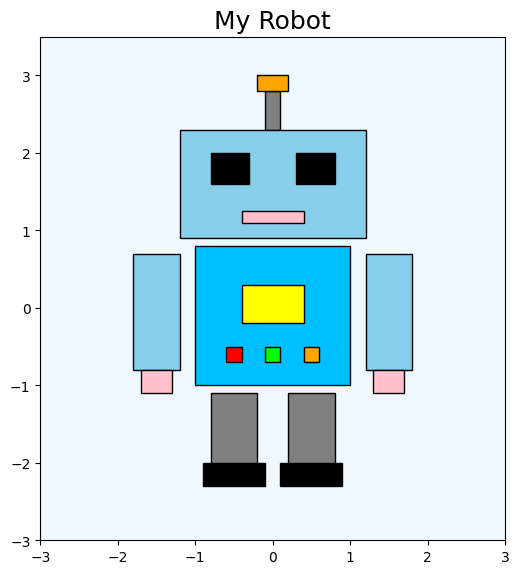

In [67]:

fig, ax = plt.subplots(figsize=(6, 7))

my_utils.draw_object(ax, np.eye(3))

ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3.5)
ax.set_aspect("equal")
ax.set_facecolor("#F0F8FF")
ax.set_title("My Robot", fontsize=18)

plt.show()


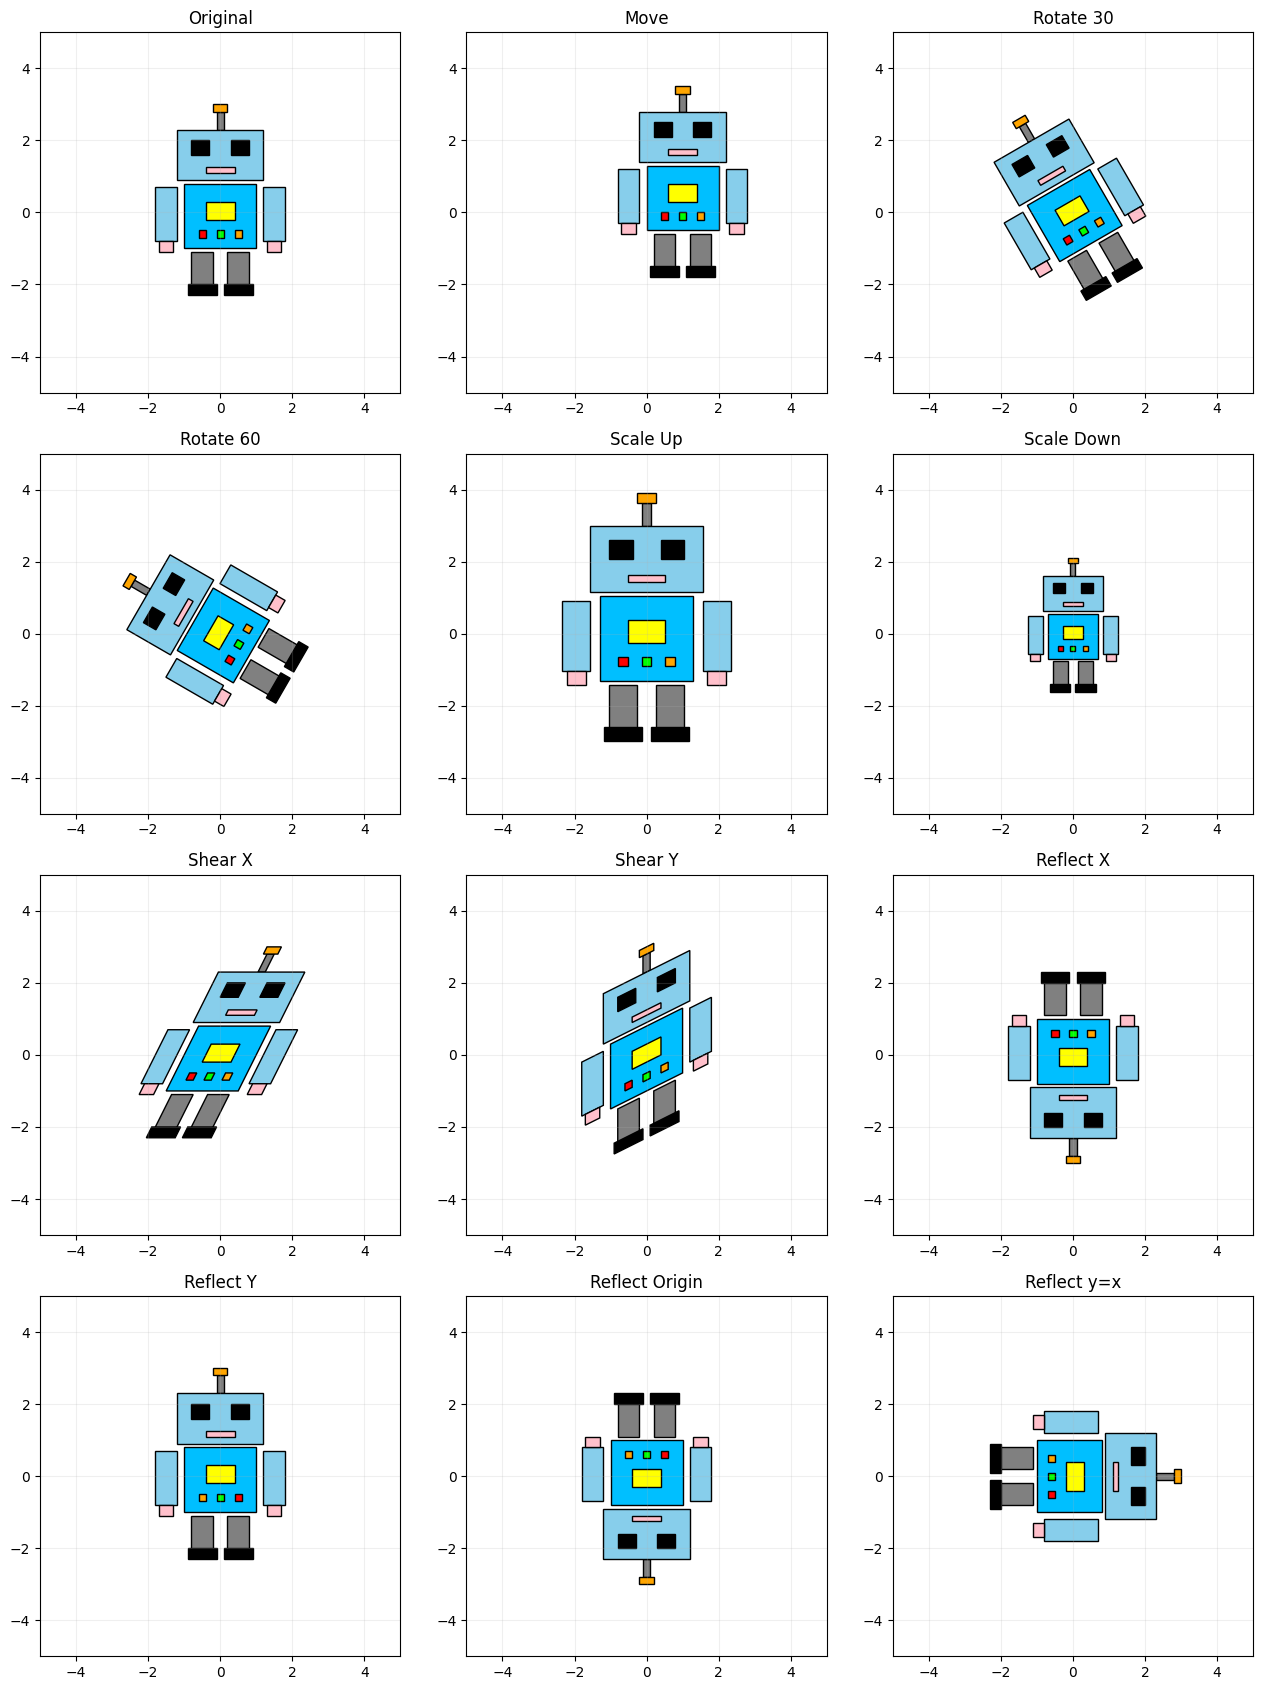

In [68]:

transformations = [
    ("Original", np.eye(3)),
    ("Move", my_utils.move(1, 0.5)),
    ("Rotate 30", my_utils.rotate(30)),
    ("Rotate 60", my_utils.rotate(60)),
    ("Scale Up", my_utils.scale(1.3, 1.3)),
    ("Scale Down", my_utils.scale(0.7, 0.7)),
    ("Shear X", my_utils.shear_x(0.5)),
    ("Shear Y", my_utils.shear_y(0.5)),
    ("Reflect X", my_utils.reflect_x()),
    ("Reflect Y", my_utils.reflect_y()),
    ("Reflect Origin", my_utils.reflect_origin()),
    ("Reflect y=x", my_utils.reflect_yx())
]

plt.figure(figsize=(13, 17))

for i, (title, M) in enumerate(transformations):

    ax = plt.subplot(4, 3, i+1)

    my_utils.draw_object(ax, M)

    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()
